# Singularity in Bohemian Upper-Hessenberg Matrices: Anatomy and Geometric Rate

Kevin Josué Martínez Herrera, School of Physics, University of Costa Rica.

This notebook walks through the computations behind the project: with what probability is a random Bohemian upper-Hessenberg matrix singular, and why. An $n\times n$ matrix $H$ is upper Hessenberg if $h_{ij}=0$ for $i>j+1$. It is Bohemian (BOunded HEight Matrix of Integers) when its free entries are drawn from a small fixed set, here $\{0,\dots,m-1\}$, uniformly and independently. Two models are compared, differing only in the subdiagonal $s_i=h_{i+1,i}$:

* **Normalized model**: $s_i=1$ (Corless-Thornton convention).
* **Free model**: $s_i\sim\mathrm{Unif}\{0,\dots,m-1\}$, so it may vanish.

The order follows the poster: the determinant recurrence, the structural results (corank and structural singularity), exact enumeration, the geometric decay $P(\text{singular})=\Theta(\gamma(m)^n)$, its decomposition with the Lyapunov exponent, the free model, the condition number and, at the end, the eigenvalue density used for Figure 1 of the poster.

The functions live in `bohemian/`. Sample sizes are controlled by `FULL`: with `FULL = False` the whole notebook runs in roughly 15 minutes on a laptop; `FULL = True` uses the sizes of the poster (mainly the $10^8$ samples of the eigenvalue density).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd()))  # the bohemian/ package sits next to this notebook

from bohemian.bohemian_analysis import (bareiss_det, exact_rank, exact_singular_probability,
                                        hessenberg_minors, make_hessenberg, why_singular)
from bohemian.bohemian_eigenvalues import bohemian_density, render
from bohemian.gamma_estimation import estimate_gamma, lyapunov, psing_rb_contribs
from bohemian.paper_experiments import condition_numbers, psing_free, psing_normalized

FULL = False  # True: poster sample sizes (slower)
COL = {2: "#c1440e", 3: "#0f6e56", 5: "#2b5c8a", 10: "#7a4fb0", 20: "#b08900"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
T0 = time.time()

## 1. The determinant recurrence

Let $d_k=\det H[1{:}k,1{:}k]$ be the $k$-th leading principal minor, with $d_0=1$. Expanding along the last column gives the continuant recurrence

$$d_k=\sum_{j=1}^{k}(-1)^{k-j}\,h_{j,k}\left(\prod_{i=j}^{k-1}s_i\right)d_{j-1},$$

which in the normalized model reduces to $d_k=\sum_{j=1}^{k}(-1)^{k-j}h_{j,k}\,d_{j-1}$. $H$ is singular if and only if $d_n=0$. Each new column injects a fresh linear combination of all the previous minors, and singularity is the event that this random sequence lands exactly on 0 at step $n$.

The recurrence is evaluated in exact integer arithmetic, so there is no rounding (a floating-point determinant is already unreliable around $n\approx 10$), and it costs $O(n^2)$ instead of the $O(n^3)$ of an LU factorization. Below, one matrix of each model, and a cross-check of the recurrence against Bareiss integer elimination.

In [2]:
rng = np.random.default_rng(1)
Hn = make_hessenberg(5, 4, normalized=True, rng=rng)
Hf = make_hessenberg(5, 4, normalized=False, rng=rng)
print("Normalized model, n=5, m=4\n", Hn, "\nminors d_0..d_5:", hessenberg_minors(Hn))
print("\nFree model, n=5, m=4\n", Hf, "\nminors d_0..d_5:", hessenberg_minors(Hf))

# Cross-check: recurrence vs Bareiss on random matrices of both models
rng = np.random.default_rng(2)
checked, mismatches = 0, 0
for n in range(2, 11):
    for m in (2, 3, 5, 10):
        for normalized in (True, False):
            for _ in range(250):
                H = make_hessenberg(n, m, normalized, rng)
                mismatches += hessenberg_minors(H)[-1] != bareiss_det(H)
                checked += 1
print(f"\nrecurrence vs Bareiss: {mismatches} mismatches in {checked:,} matrices")

Normalized model, n=5, m=4
 [[1 2 3 3 0]
 [1 0 3 3 0]
 [0 1 1 3 1]
 [0 0 1 1 3]
 [0 0 0 1 1]] 
minors d_0..d_5: [1, 1, -2, -2, 4, 8]

Free model, n=5, m=4
 [[1 2 2 0 0]
 [0 3 3 3 2]
 [0 1 3 1 1]
 [0 0 3 3 0]
 [0 0 0 0 1]] 
minors d_0..d_5: [1, 1, 3, 6, 18, 18]



recurrence vs Bareiss: 0 mismatches in 18,000 matrices


## 2. Structural theory of the normalized model

The question "why is a singular matrix singular?" splits into structural causes (a zero row or column, two equal or proportional rows or columns) and genuine arithmetic dependence. For the normalized model two short arguments settle it.

**Theorem 1 (corank at most one).** Deleting the first row and the last column leaves an $(n-1)\times(n-1)$ block on rows $2,\dots,n$ and columns $1,\dots,n-1$. Its diagonal is the subdiagonal of $H$, all ones, and everything below it vanishes by the Hessenberg shape, so it is upper triangular with unit diagonal and determinant 1. Hence $\operatorname{rank}(H)\geq n-1$, and a singular $H$ has a kernel of dimension exactly 1.

**Theorem 2 (structural singularity is exponentially rare).** Rows $2,\dots,n$ carry their forced 1 in distinct columns and are zero before it, so no two of them are equal, proportional or zero. A structural event therefore involves row 1: it vanishes, or it is $c$ times some row $j\geq2$. Row $j$ is zero up to column $j-2$, has the forced 1 in column $j-1$ and free entries after it, so $\text{row}_1=c\,\text{row}_j$ fixes all $n$ entries of row 1. The same holds for columns, where only column $n$ lacks a subdiagonal 1: it vanishes or is a multiple of some column $k\leq n-1$. Each channel fixes $n$ independent entries, so it has probability at most $m^{-n}$, and with $n-1$ partners and $m-1$ possible multipliers on each side
$$P(\text{structural})\leq\bigl(2(n-1)(m-1)+2\bigr)\,m^{-n}=O(n\,m^{1-n}).$$
The poster states this as $O(m^{-n})$, counting only the partner row 2 and column $n-1$. Row 1 can also coincide with a later row once its first entries vanish, which adds the factor $n$. The conclusion does not change, since the bound is still exponentially small next to the total probability.

Both are checked numerically: the exact rank over $\mathbb{Q}$ of sampled singular matrices, and the classification of why each one is singular.

In [3]:
from collections import Counter

rng = np.random.default_rng(3)
print(f"{'n':>2} {'m':>3} {'singular':>9} {'corank=1':>9} {'P(sing)':>8} {'struct.':>8}"
      f" {'P(struct)':>10} {'bound':>8}  reasons")
for n, m in [(4, 2), (6, 2), (8, 2), (10, 2), (4, 3), (6, 3), (8, 3), (6, 5)]:
    tries, singular, reasons, corank_one = 0, 0, Counter(), 0
    while singular < 400:
        H = make_hessenberg(n, m, normalized=True, rng=rng)
        tries += 1
        if hessenberg_minors(H)[-1] == 0:
            singular += 1
            corank_one += exact_rank(H) == n - 1
            reasons[why_singular(H)] += 1
    frac = 1 - reasons["genuine"] / singular  # fraction of singular matrices with a structural cause
    p = singular / tries
    print(f"{n:>2} {m:>3} {singular:>9} {corank_one:>9} {p:>8.4f} {frac:>8.3f}"
          f" {frac * p:>10.2e} {(2 * (n - 1) * (m - 1) + 2) * m**-n:>8.1e}  {dict(sorted(reasons.items()))}")

 n   m  singular  corank=1  P(sing)  struct.  P(struct)    bound  reasons
 4   2       400       400   0.4188    0.863   3.61e-01  5.0e-01  {'equal_col': 84, 'equal_row': 140, 'genuine': 55, 'zero_rowcol': 121}
 6   2       400       400   0.3518    0.458   1.61e-01  1.9e-01  {'equal_col': 59, 'equal_row': 90, 'genuine': 217, 'zero_rowcol': 34}


 8   2       400       400   0.2869    0.245   7.03e-02  6.2e-02  {'equal_col': 41, 'equal_row': 43, 'genuine': 302, 'zero_rowcol': 14}


10   2       400       400   0.2380    0.075   1.78e-02  2.0e-02  {'equal_col': 11, 'equal_row': 16, 'genuine': 370, 'zero_rowcol': 3}
 4   3       400       400   0.1894    0.682   1.29e-01  1.7e-01  {'equal_col': 85, 'equal_row': 80, 'genuine': 127, 'prop_col': 23, 'prop_row': 23, 'zero_rowcol': 62}


 6   3       400       400   0.1118    0.172   1.93e-02  3.0e-02  {'equal_col': 21, 'equal_row': 28, 'genuine': 331, 'prop_col': 7, 'prop_row': 7, 'zero_rowcol': 6}


 8   3       400       400   0.0671    0.032   2.18e-03  4.6e-03  {'equal_col': 6, 'equal_row': 3, 'genuine': 387, 'prop_col': 2, 'prop_row': 1, 'zero_rowcol': 1}


 6   5       400       400   0.0178    0.052   9.33e-04  2.7e-03  {'equal_col': 5, 'equal_row': 5, 'genuine': 379, 'prop_col': 2, 'prop_row': 6, 'zero_rowcol': 3}


Every sampled singular matrix has corank exactly 1, as Theorem 1 forces. The structural reasons that appear are the channels of Theorem 2: row 1 or column $n$ zero (`zero_rowcol`), row 1 equal or proportional to a later row (`equal_row`, `prop_row`), and column $n$ equal or proportional to an earlier column (`equal_col`, `prop_col`). At small $n$ they are a large share of the singular matrices, but their probability `P(struct)` stays below the bound of Theorem 2 (`bound`) up to sampling error (each row uses 400 singular matrices; for $n=8$, $m=2$ a run with $6	imes10^4$ matrices gives $0.0607\pm0.0010$ against $0.0625$), and the bound decays like $n\,m^{-n}$, while the total singularity probability decays only as $\gamma(m)^n$ with $\gamma(m)\gg m^{-1}$ (Section 4). So the structural fraction (`struct.`) goes to 0 with $n$, as the $m=2$ and $m=3$ rows show: conditioned on being singular, a normalized $H$ is almost surely singular for a genuine reason (Corollary 1). This is the opposite of the dense fixed-alphabet case, where singularity is dominated to leading order by structural collisions (Tikhomirov).

## 3. Exact enumeration and the $1/m$ bound

**Theorem 3.** In the normalized model $P(H\text{ singular})\leq 1/m$ for all $n,m$. The coefficient of $h_{1,n}$ in $d_n$ is $(-1)^{n-1}d_0=\pm1$, so $d_n=\pm h_{1,n}+R$ with $R$ independent of $h_{1,n}$. Since $h_{1,n}$ takes each of its $m$ values with probability $1/m$, $P(d_n=0)=\tfrac1m P(\mp R\in\{0,\dots,m-1\})\leq 1/m$.

For small $(n,m)$ the whole family ($m^{n(n+1)/2}$ matrices) is enumerated and the probability is obtained as an exact rational. This is the ground truth for the sampled estimates below. The bound is attained at $n=m=2$: $d_2=h_{11}h_{22}-h_{12}$, and over $\{0,1\}$ the product $h_{11}h_{22}$ always lands in the alphabet, so exactly one of the two values of $h_{12}$ cancels it.

In [4]:
print(f"{'n':>2} {'m':>2} {'matrices':>9} {'P(det H = 0)':>14} {'decimal':>8} {'1/m':>6}")
EXACT = {}
for n, m in [(2, 2), (2, 3), (2, 5), (3, 2), (3, 3), (4, 2), (4, 3), (5, 2), (6, 2)]:
    p = exact_singular_probability(n, m, normalized=True)
    EXACT[(n, m)] = p
    print(f"{n:>2} {m:>2} {m ** (n * (n + 1) // 2):>9,} {str(p):>14} {float(p):>8.4f} {1 / m:>6.3f}")

 n  m  matrices   P(det H = 0)  decimal    1/m
 2  2         8            1/2   0.5000  0.500
 2  3        27           8/27   0.2963  0.333
 2  5       125         17/125   0.1360  0.200
 3  2        64          15/32   0.4688  0.500
 3  3       729          19/81   0.2346  0.333
 4  2     1,024         55/128   0.4297  0.500
 4  3    59,049    10772/59049   0.1824  0.333
 5  2    32,768      1599/4096   0.3904  0.500
 6  2 2,097,152  185183/524288   0.3532  0.500


## 4. Geometric decay

The singularity probability of the normalized model is estimated by Monte Carlo with the exact recurrence (batched `int64`, which is exact in these ranges; the code checks the Hadamard bound). On a semilog scale the points align, i.e. $P(\det H=0)=\Theta(\gamma(m)^n)$. The rows $n\leq 6$, $m=2$ can be compared against the exact values above. For $m=20$ the probability at $n=8$ is $\sim10^{-6}$, too rare for plain counting, so that column uses the Rao-Blackwell estimator described below.

 n        m=2        m=3        m=5       m=10       m=20
 3  4.709e-01  2.348e-01  7.964e-02  1.504e-02           
 4  4.301e-01  1.827e-01  4.687e-02  5.653e-03           
 5  3.905e-01  1.415e-01  2.791e-02  2.173e-03   1.46e-04
 6  3.535e-01  1.104e-01  1.659e-02  8.920e-04           
 7  3.188e-01  8.482e-02  1.017e-02  3.267e-04           
 8  2.877e-01  6.724e-02  6.343e-03  1.447e-04   1.80e-06
 9  2.581e-01  5.200e-02  3.771e-03  5.467e-05           

exact (m=2): n=3: 0.4688, n=4: 0.4297, n=5: 0.3904, n=6: 0.3532


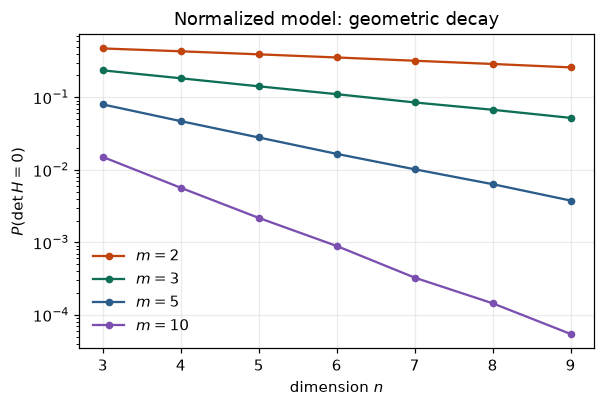

In [5]:
rng = np.random.default_rng(2025)
ns = list(range(3, 10))
Ksamp = {2: 300_000, 3: 400_000, 5: 800_000, 10: 1_500_000}
P = {m: [psing_normalized(n, m, Ksamp[m], rng=rng) for n in ns] for m in Ksamp}
# m = 20 is too rare for plain counting at n = 8; the Rao-Blackwell estimator of Section 4 is used
P20 = {n: psing_rb_contribs(n, 20, K, rng=rng).mean() for n, K in [(5, 3_000_000), (8, 12_000_000)]}

print(f"{'n':>2} " + " ".join(f"{'m=' + str(m):>10}" for m in Ksamp) + f" {'m=20':>10}")
for i, n in enumerate(ns):
    p20 = f"{P20[n]:>10.2e}" if n in P20 else f"{'':>10}"
    print(f"{n:>2} " + " ".join(f"{P[m][i]:>10.3e}" for m in Ksamp) + " " + p20)
print("\nexact (m=2): " + ", ".join(f"n={n}: {float(EXACT[(n, 2)]):.4f}" for n in (3, 4, 5, 6)))

fig, ax = plt.subplots(figsize=(5.6, 3.8))
for m in Ksamp:
    ax.semilogy(ns, P[m], "o-", color=COL[m], label=f"$m={m}$", lw=1.5, ms=4)
ax.set_xlabel("dimension $n$")
ax.set_ylabel(r"$P(\det H=0)$")
ax.set_title("Normalized model: geometric decay")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Rao-Blackwell estimation of $\gamma(m)$

To estimate the base $\gamma(m)$ precisely, $h_{1,n}$ is integrated analytically instead of sampled. Writing $d_n=(-1)^{n-1}h_{1,n}+R$,

$$P(d_n=0\mid\text{rest})=\tfrac1m\,\mathbf 1\{(-1)^nR\in\{0,\dots,m-1\}\},$$

so each sample contributes $0$ or $1/m$ instead of $0$ or $1$, which cuts the variance by a factor of about $m$. Then $\log P(n)=a+n\log\gamma+\alpha\log n$ is fitted (the $\log n$ term separates the geometric base from a polynomial prefactor), with 95% bootstrap intervals. Since every contribution is $0$ or $1/m$, the bootstrap resamples are drawn as binomial counts, which has the same distribution as resampling the contributions.

  m   gamma            95% CI  alpha  gamma*sqrt(m)
  2   0.894 [0.892, 0.896]   0.07          1.264
  3   0.793 [0.787, 0.799]  -0.12          1.373
  5   0.635 [0.619, 0.650]  -0.29          1.419
 10   0.430 [0.394, 0.471]  -0.48          1.361


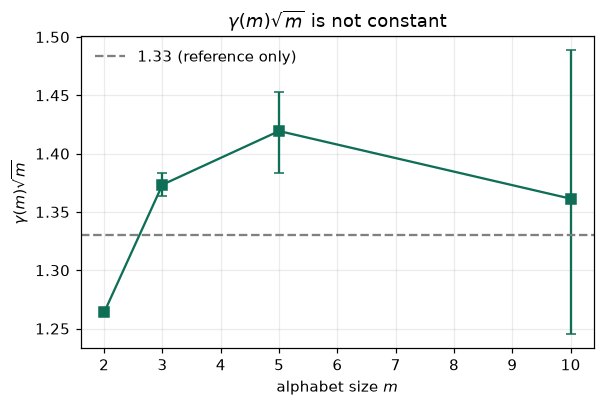

In [6]:
rng = np.random.default_rng(20260803)
plans = {2: (range(5, 15), 500_000), 3: (range(5, 13), 700_000),
         5: (range(5, 12), 1_000_000), 10: (range(4, 11), 1_500_000)}
G = {m: estimate_gamma(m, list(r), K, rng=rng) for m, (r, K) in plans.items()}

print(f"{'m':>3} {'gamma':>7} {'95% CI':>17} {'alpha':>6} {'gamma*sqrt(m)':>14}")
for m, g in G.items():
    print(f"{m:>3} {g['gamma']:>7.3f} [{g['ci'][0]:.3f}, {g['ci'][1]:.3f}] {g['alpha']:>6.2f}"
          f" {g['gamma'] * np.sqrt(m):>14.3f}")

ms = list(G)
gs = np.array([G[m]["gamma"] for m in ms])
lo = np.array([G[m]["ci"][0] for m in ms])
hi = np.array([G[m]["ci"][1] for m in ms])
fig, ax = plt.subplots(figsize=(5.6, 3.8))
sq = np.sqrt(ms)
ax.errorbar(ms, gs * sq, yerr=[(gs - lo) * sq, (hi - gs) * sq], fmt="s-", color="#0f6e56", capsize=3)
ax.axhline(1.33, ls="--", color="gray", label="1.33 (reference only)")
ax.set_xlabel("alphabet size $m$")
ax.set_ylabel(r"$\gamma(m)\sqrt{m}$")
ax.set_title(r"$\gamma(m)\sqrt{m}$ is not constant")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

The base $\gamma(m)$ is far above the $1/m$ of the dense model (e.g. $\gamma(10)\approx 0.4$ against $0.1$), so the Hessenberg constraint makes singularity much more common. However, $\gamma(m)\sqrt m$ is not constant over the tested range, so a clean $m^{-1/2}$ law is not supported. This is a statement about small alphabets only: at $m=20$ the probability is already $\sim10^{-4}$ at $n=5$, so $\gamma$ cannot be pinned down there with exact sampling, and small alphabets are exactly where divisibility effects among the minors are strongest.

## 5. Mechanism: Lyapunov exponent and arithmetic resonance

From Theorem 3, $P(d_n=0)=\tfrac1m\,\mathbb E\left[P(R\in\{0,\dots,m-1\})\right]$, where $R$ is an integer whose scale is set by $|d_{n-1}|$. The minors grow exponentially with the Lyapunov exponent

$$\lambda(m)=\lim_{k\to\infty}\frac1k\log|d_k|$$

(read as an almost-sure growth rate, since $d_k=0$ has positive probability). Landing in a fixed window of an exponentially large range suggests the decomposition

$$\gamma(m)=e^{-\lambda(m)}\rho(m),\qquad \rho(m)\geq1,$$

with $\rho$ an arithmetic-resonance factor. $\lambda(m)$ is estimated at dimensions up to $n=1000$ (feasible thanks to the $O(n^2)$ recurrence) with per-step rescaling of the minor vector, drawing one column per step. The estimate is reported at $n=250, 500, 1000$ to show that it is stable.

  m  lambda(250)  lambda(500)  lambda(1000)     s.e.  e^-lambda   gamma    rho      rho 95% CI
  2       0.1112       0.1136        0.1148  9.7e-05      0.892   0.894   1.00 [1.00, 1.00]
  3       0.2667       0.2684        0.2688  1.8e-04      0.764   0.793   1.04 [1.03, 1.04]
  5       0.5839       0.5852        0.5844  3.4e-04      0.557   0.635   1.14 [1.11, 1.17]
 10       1.1740       1.1744        1.1748  5.1e-04      0.309   0.430   1.39 [1.28, 1.52]


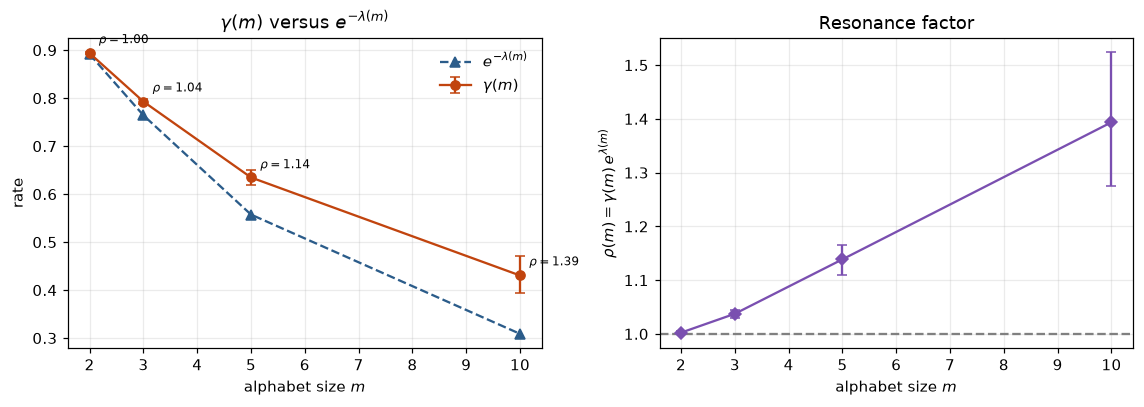

In [7]:
rng = np.random.default_rng(7)
LAM = {m: lyapunov(m, n=1000, K=4000 if FULL else 2000, rng=rng) for m in ms}

print(f"{'m':>3} {'lambda(250)':>12} {'lambda(500)':>12} {'lambda(1000)':>13} {'s.e.':>8}"
      f" {'e^-lambda':>10} {'gamma':>7} {'rho':>6} {'rho 95% CI':>15}")
RHO = {}
for m in ms:
    lam, se = LAM[m][1000]
    e = np.exp(lam)
    RHO[m] = (G[m]["gamma"] * e, G[m]["ci"][0] * e, G[m]["ci"][1] * e)
    print(f"{m:>3} {LAM[m][250][0]:>12.4f} {LAM[m][500][0]:>12.4f} {lam:>13.4f} {se:>8.1e}"
          f" {1 / e:>10.3f} {G[m]['gamma']:>7.3f} {RHO[m][0]:>6.2f} [{RHO[m][1]:.2f}, {RHO[m][2]:.2f}]")

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax = axs[0]
ax.errorbar(ms, gs, yerr=[gs - lo, hi - gs], fmt="o-", color="#c1440e", capsize=3, label=r"$\gamma(m)$")
ax.plot(ms, [np.exp(-LAM[m][1000][0]) for m in ms], "^--", color="#2b5c8a", label=r"$e^{-\lambda(m)}$")
for m in ms:
    ax.annotate(rf"$\rho={RHO[m][0]:.2f}$", (m, G[m]["gamma"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("alphabet size $m$")
ax.set_ylabel("rate")
ax.set_title(r"$\gamma(m)$ versus $e^{-\lambda(m)}$")
ax.legend(frameon=False)
ax = axs[1]
r = np.array([RHO[m] for m in ms])
ax.errorbar(ms, r[:, 0], yerr=[r[:, 0] - r[:, 1], r[:, 2] - r[:, 0]], fmt="D-", color="#7a4fb0", capsize=3)
ax.axhline(1, ls="--", color="gray")
ax.set_xlabel("alphabet size $m$")
ax.set_ylabel(r"$\rho(m)=\gamma(m)\,e^{\lambda(m)}$")
ax.set_title("Resonance factor")
plt.tight_layout()
plt.show()

$\lambda(m)$ is stable from $n\approx250$ on, with standard errors around $10^{-3}$, two orders of magnitude below the uncertainty of $\gamma$, so the interval of $\rho$ is propagated from $\gamma$ only. The naive guess $\rho=1$ ($\gamma=e^{-\lambda}$) holds at $m=2$ but $\rho$ grows with $m$: singularity is more likely than growth alone predicts, because the minors share arithmetic structure that concentrates $R$ on a sublattice and enlarges its atom at 0.

**Conjecture 1.** For each $m\geq2$ the limit $\gamma(m)=\lim_n P(d_n=0)^{1/n}$ exists and $\gamma(m)=e^{-\lambda(m)}\rho(m)$, with $\rho(m)\geq1$. This is not a corollary of standard theory: the existence of exponential rates for random products usually comes from Furstenberg-Kesten, Oseledets or Kingman, which need stationary maps on a fixed space. Here $D_k=(d_k,\dots,d_0)$ has dimension $k+1$, growing at every step, so none of them applies directly.

## 6. The free model: structure comes back

With a random subdiagonal, a single $s_i=0$ makes $H$ block triangular, and $H$ is singular whenever either block is. Since $P(\exists\, s_i=0)\approx(n-1)/m$, singularity becomes structural and grows with $n$, and the corank can exceed 1. Below: the singularity probability of both models, the fraction of singular free matrices that carry a zero subdiagonal entry, and the exact corank of a sample of singular free matrices.

 m  n   P free  P normalized  zero s_i | singular  corank counts
 3  3   0.4162        0.2348                0.748  {1: 279, 2: 21}
 3  4   0.4566        0.1827                0.882  {1: 272, 2: 28}
 3  5   0.4924        0.1415                0.946  {1: 281, 2: 19}
 3  6   0.5321        0.1104                0.973  {1: 279, 2: 21}
 3  7   0.5661        0.0848                0.988  {1: 273, 2: 27}
 3  8   0.5978        0.0672                0.994  {1: 270, 2: 29, 3: 1}
 3  9   0.6309        0.0520                0.997  {1: 267, 2: 33}
 5  3   0.1690        0.0796                0.699  {1: 294, 2: 6}
 5  4   0.1708        0.0469                0.863  {1: 294, 2: 6}
 5  5   0.1775        0.0279                0.942  {1: 300}
 5  6   0.1889        0.0166                0.975  {1: 298, 2: 2}
 5  7   0.1989        0.0102                0.989  {1: 295, 2: 5}
 5  8   0.2139        0.0063                0.996  {1: 297, 2: 3}
 5  9   0.2232        0.0038                0.998  {1: 296, 2: 4}


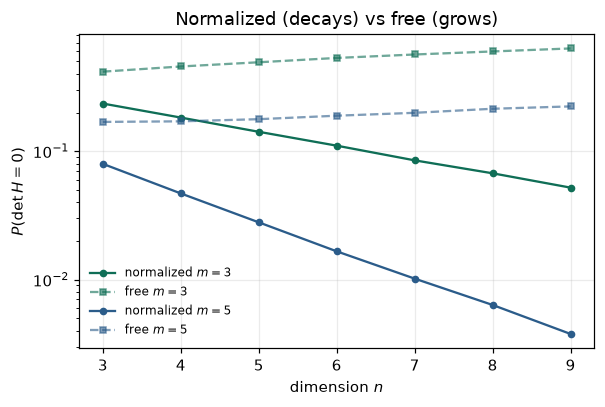

In [8]:
rng = np.random.default_rng(11)
PF, ZERO, CORANK = {}, {}, {}
for m in (3, 5):
    PF[m], ZERO[m], CORANK[m] = [], [], []
    for n in ns:
        p, frac, mats = psing_free(n, m, 150_000, rng=rng, return_samples=300)
        PF[m].append(p)
        ZERO[m].append(frac)
        CORANK[m].append(Counter(n - exact_rank(M) for M in mats))

print(f"{'m':>2} {'n':>2} {'P free':>8} {'P normalized':>13} {'zero s_i | singular':>20}  corank counts")
for m in (3, 5):
    for i, n in enumerate(ns):
        print(f"{m:>2} {n:>2} {PF[m][i]:>8.4f} {P[m][i]:>13.4f} {ZERO[m][i]:>20.3f}  {dict(sorted(CORANK[m][i].items()))}")

fig, ax = plt.subplots(figsize=(5.6, 3.8))
for m in (3, 5):
    ax.semilogy(ns, P[m], "o-", color=COL[m], lw=1.5, ms=4, label=f"normalized $m={m}$")
    ax.semilogy(ns, PF[m], "s--", color=COL[m], lw=1.5, ms=4, alpha=0.6, label=f"free $m={m}$")
ax.set_xlabel("dimension $n$")
ax.set_ylabel(r"$P(\det H=0)$")
ax.set_title("Normalized (decays) vs free (grows)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The two models are the structural phase and the genuine phase of the same object, separated by one modeling choice. Reducing the band to the tridiagonal case does not keep the phenomenon either: the last column has only two free entries and vanishes with probability $1/m^2$. The dense upper triangle is what matters.

## 7. Condition number

The singularity mechanism controls the lower edge of the singular-value spectrum and hence the condition number $\kappa=\sigma_{\max}/\sigma_{\min}$. Singular values are computed by SVD on batches of normalized matrices with $n=6$. The exactly singular matrices are flagged by the integer recurrence and removed before the SVD, so the atom at $\kappa=\infty$ does not leak into the bulk through floating-point noise.

This is the conditioning of the maximally random member of the upper-Hessenberg shape class. It is a baseline, not a model of the Hessenberg matrices produced by Arnoldi or GMRES, whose entries are correlated and inherit the spectrum of the operator.

The separation matters for $m=2$, where about a third of the matrices are exactly singular: keeping them (their floating-point $\sigma_{\min}$ is tiny but not zero) moves the median $\kappa$ from about 10 to about 13, the value given in the write-up. For $m=5$ and $m=10$ the difference is negligible.

  m  median kappa               IQR  exactly singular


  2          10.1 [   7.8,    13.0]            0.3536


  3          25.1 [  16.4,    42.0]            0.1092


  5          58.8 [  32.8,   124.4]            0.0175


 10         117.4 [  53.3,   313.5]            0.0009


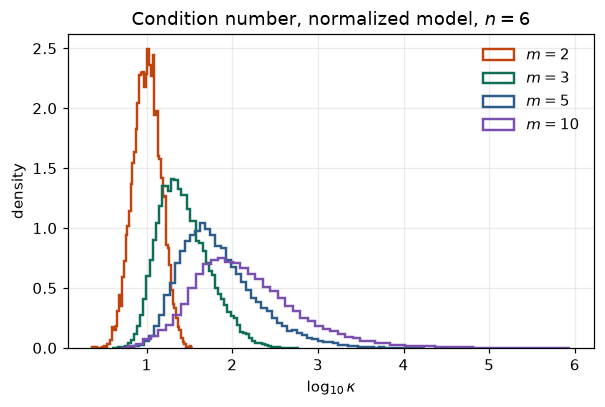

In [9]:
rng = np.random.default_rng(13)
fig, ax = plt.subplots(figsize=(5.6, 3.8))
print(f"{'m':>3} {'median kappa':>13} {'IQR':>17} {'exactly singular':>17}")
for m in (2, 3, 5, 10):
    ks, n_sing = condition_numbers(6, m, 40_000, normalized=True, rng=rng)
    q1, q2, q3 = np.percentile(ks, [25, 50, 75])
    print(f"{m:>3} {q2:>13.1f} [{q1:>6.1f}, {q3:>7.1f}] {n_sing / 40_000:>17.4f}")
    ax.hist(np.log10(ks), bins=60, histtype="step", lw=1.6, color=COL[m], label=f"$m={m}$", density=True)
ax.set_xlabel(r"$\log_{10}\kappa$")
ax.set_ylabel("density")
ax.set_title(r"Condition number, normalized model, $n=6$")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Eigenvalue density

Not part of the singularity analysis, but it places the family in the Bohemian tradition: the empirical eigenvalue density of the normalized family for $n=5$, alphabet $\{0,1,2,3\}$ ($m=4$). Eigenvalues are accumulated into a fixed 2D histogram, so $10^8$ samples never have to be stored at once. The eigenvalues cluster near the real axis, with circular voids around the small integers.

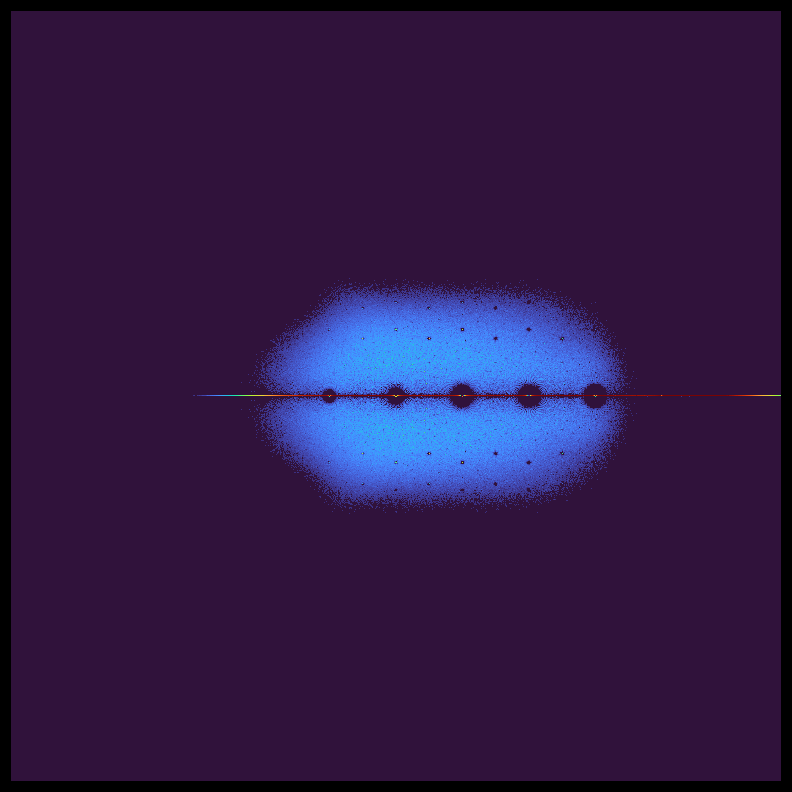

10,000,000 matrices, extent = 5.79, total time of the notebook: 8.7 min


In [10]:
N_EIG = 100_000_000 if FULL else 10_000_000
Hist, ext = bohemian_density(5, [0, 1, 2, 3], num_samples=N_EIG, bins=1400, structure="hessenberg", seed=4)
fig = render(Hist, ext, None, cmap="turbo", gamma=0.3, size=7)
plt.show()
print(f"{N_EIG:,} matrices, extent = {ext:.2f}, total time of the notebook: {(time.time() - T0) / 60:.1f} min")

## Summary

* Normalized model: corank $\leq1$ always, structural singularity is $O(m^{-n})$, and $P(\text{singular})\leq1/m$, attained at $n=m=2$. A singular normalized matrix is singular for a genuine arithmetic reason, unlike the dense i.i.d. case.
* $P(\text{singular})=\Theta(\gamma(m)^n)$ with $\gamma(m)$ far above $1/m$; $\gamma(m)\sqrt m$ is not constant over $m\leq10$.
* $\gamma(m)=e^{-\lambda(m)}\rho(m)$ separates the growth of the minors from an arithmetic-resonance factor that goes from $\rho\approx1$ at $m=2$ upward. The existence of $\gamma(m)$ is a conjecture, because the state vector of the recurrence grows in dimension at every step.
* The free model goes back to structural singularity, so the dense upper triangle, not the Hessenberg shape alone, drives the phenomenon.
* The condition number grows with $m$; it is offered as a null-model baseline for Krylov and open-system reductions, not as a model of them.